In [ ]:
import numpy as np
import matplotlib.pyplot as plt



Task 1 - GD on a curve with two valleys

In [ ]:
L = lambda w: (w ** 2 - 1) ** 2
g = lambda w: 4*w**3 - 4*w
assert abs(g(0.5) - (-1.5)) < 1e-9, f"Error, g(0.5) != -1.5 "

1.
eta = 0.1

w0 = 0.5

step 1:

w = 0.5 - 0.1 * (4 * 0.5**3 - 4 * 0.5) = 0.65

L = (0.65 ** 2 - 1) ** 2 = 0.333506

step 2:

w = 0.65 - 0.1 * (4 * 0.65**3 - 4 * 0.65) = 0.8

L = (0.8 ** 2 - 1) ** 2 = 0.1296

2. It will be the same, as the reflection of w0 = 0.5 with the same learning rate relatively to the oy axis. Because we have even Loss function and odd gradient function, which means that first is symmetric relatively to w = 0 and the second is symmetric relatively to (0,0).

3.

1) eta = 0.1; w0 = 1.5; g = 7.5;

w = 1.5 - 0.1 * (4*1.5**3 - 4*1.5) = 0.75

It goes to the right

2) eta = 0.2;

w = 1.5 - 0.2 * (4*1.5**3 - 4*1.5) = 0

it is on the bump

3) eta = 0.24;

w = 1.5 - 0.24 * (4*1.5**3 - 4*1.5) = -0.3

it goes to the left

In [ ]:
runs = [
    (0.1,  0.5),
    (0.1, -0.5),
    (0.1,  1.5),
    (0.2,  1.5),
    (0.24, 1.5),
]

In [ ]:
def gd(w0, eta, n_steps=30):
    points = [w0]
    w = w0
    for _ in range(n_steps):
        w = w - eta * g(w)
        points.append(w)
    return np.array(points)


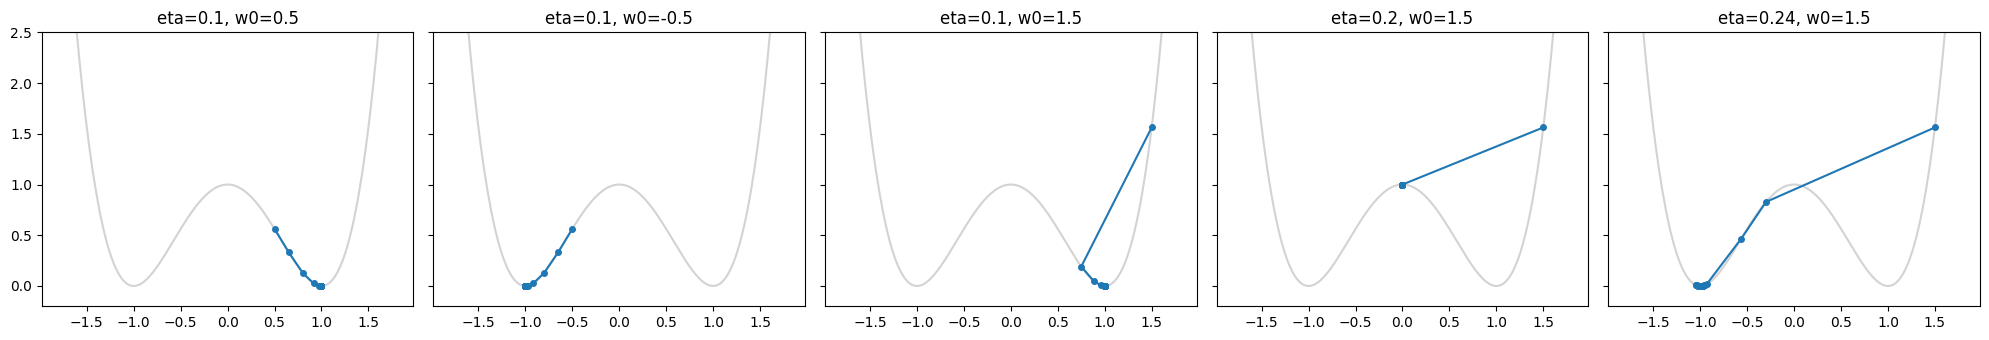

In [ ]:
w_grid = np.linspace(-1.8, 1.8, 200)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
for ax, (eta, w0) in zip(axes, runs):
    pts = gd(w0, eta)
    ax.plot(w_grid, L(w_grid), color="lightgray")
    ax.plot(pts, L(pts), "o-", ms=4)
    ax.set_title(f"eta={eta}, w0={w0}")
    ax.set_ylim(-0.2, 2.5)
plt.tight_layout()
plt.show()

**Which valley does each run end in? What decides it?**

at w = -1 and w = 1. Because at these points loss has it's local minimum. And one of the run came to w = 0. Several factors decides it. First, on which side we start (w0) and second, learning rate (the value of our step).

**The run with eta = 0.2 stops at w = 0. Is that a minimum? What does this tell you about points where the gradient is zero?**

No, it is our local max. But it is our critical point (gradient at htis point equals to 0) and because algorithm can't distinguish between max and min and just finds points at which gradient = 0 we stop there.

**Where on the curve is the gradient lardest, and where is it zero? Use your plots to answer.**

The gradient is largest on the third plot with eta = 0.1 and w0 = 1.5 and the gradient is zero exactly at w = -1, 0, +1

Task 2 - GD on a surface

start = (2,1)

**eta = 0.05**

*step 1*

g(2,1) = (4, 20)

w1 = 2 - 0.05 * 4 = 1.8

w2 = 1 - 0.05 * 20 = 0

L = 1.8 ** 2 + 10 * 0 **2 = 3.24

*step 2*

g(1.8, 0) = (3.6, 0)

w1 = 1.8 - 0.05 * 3.6 = 1.62

w2 = 0 - 0.05 * 0 = 0

L = 1.62 ** 2=2.6244

**eta = 0.09**

*step 3*

g(1.62, 0) = (3.24, 0)

w1 = 1.62 - 0.09 * 3.24 = 1.3284

w2 = 0 - 0.09 * 0 = 0

L = 1.3284 ** 2 = 1.7647



In [ ]:
L = lambda w1, w2: w1**2 + 10 * w2**2


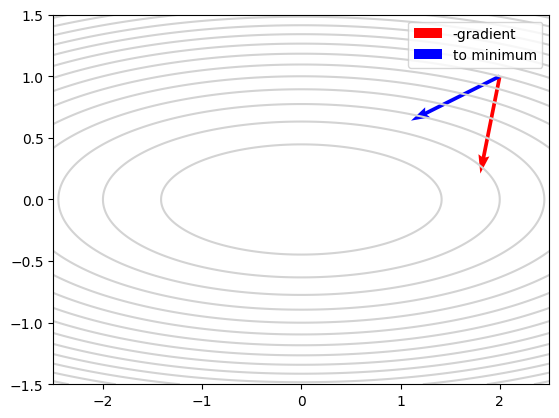

In [ ]:
w1, w2 = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-1.5, 1.5, 200))
plt.contour(w1, w2, w1**2 + 10 * w2**2, levels=15, colors="lightgray")

start = np.array([2, 1])
neg_grad = np.array([-4, -20])
to_min = np.array([0, 0]) - start

neg_grad_norm = neg_grad / np.linalg.norm(neg_grad)
to_min_norm = to_min / np.linalg.norm(to_min)

plt.quiver(*start, *neg_grad_norm, color="red", scale=5, label="-gradient")
plt.quiver(*start, *to_min_norm, color="blue", scale=5, label="to minimum")
plt.legend()
plt.xlim(-2.5, 2.5); plt.ylim(-1.5, 1.5)
plt.show()

In [ ]:
def gd2d(w0, eta, n_steps=30):
    path = [w0]
    w = np.array(w0, dtype=float)
    for _ in range(n_steps):
        grad = np.array([2*w[0], 20*w[1]])
        w = w - eta * grad
        path.append(w.copy())
    return np.array(path)   #

etas = [0.01, 0.05, 0.09, 0.11]
w0 = (2, 1)
paths = {eta: gd2d(w0, eta) for eta in etas}

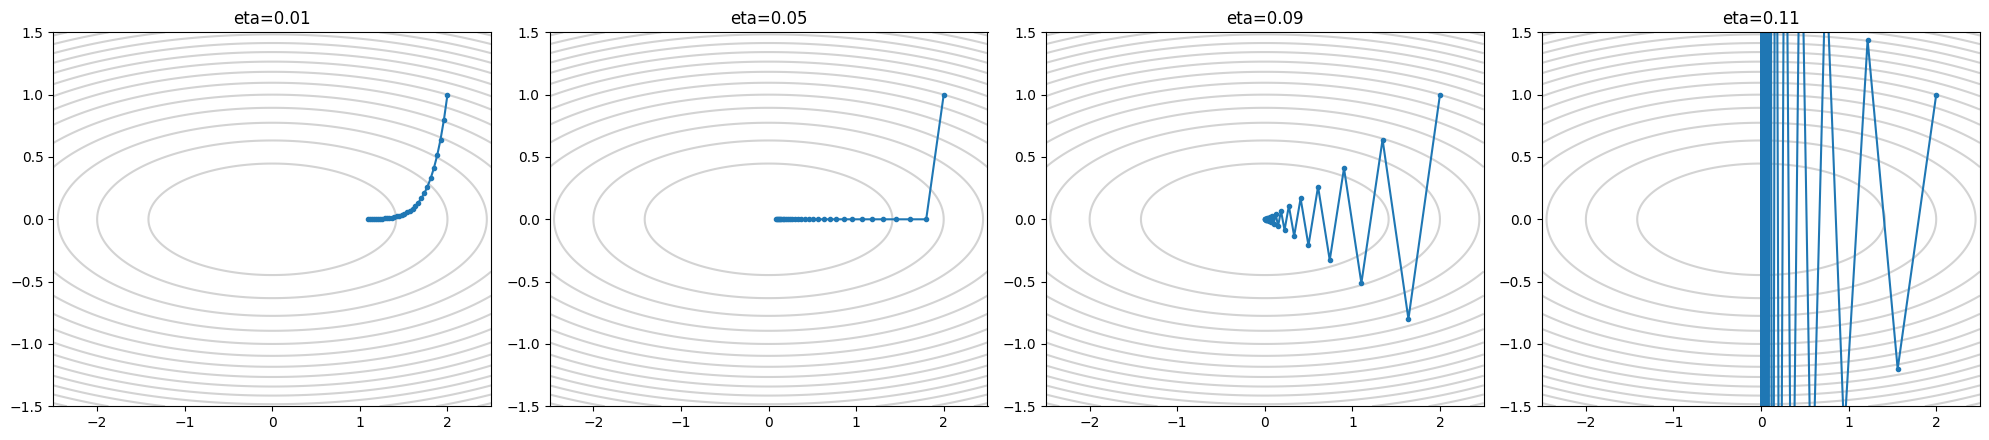

In [ ]:
w1, w2 = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-1.5, 1.5, 200))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, eta in zip(axes, etas):
    path = paths[eta]
    ax.contour(w1, w2, w1**2 + 10*w2**2, levels=15, colors="lightgray")
    ax.plot(path[:, 0], path[:, 1], "o-", markersize=3)
    ax.set_title(f"eta={eta}")
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.5, 1.5)
plt.tight_layout()
plt.show()

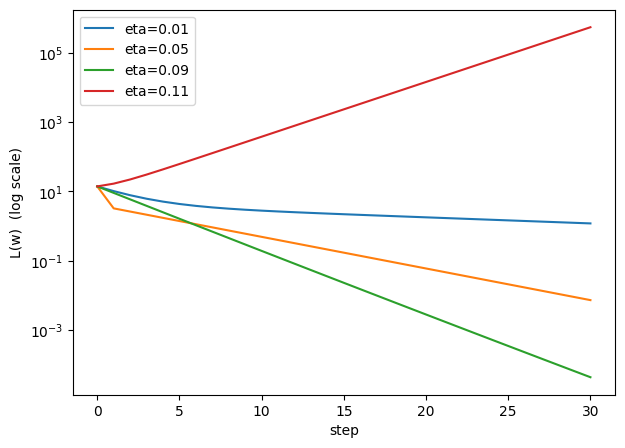

In [ ]:
plt.figure(figsize=(7, 5))
for eta in etas:
    path = paths[eta]
    L_vals = path[:, 0]**2 + 10 * path[:, 1]**2
    plt.plot(L_vals, label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("step"); plt.ylabel("L(w)  (log scale)")
plt.legend()
plt.show()

**Why does the path not head straight to the minimum? Which learning rate is too slow which zig-zags, and which blows up? In which direction, w1 or w2, does the zig-zag happen, and why that one?**

Because the surface is much steeper in the w2 direction than in w1 (w2 has 10 as coefficient).

eta = 0.01 is too slow

eta = 0.05 and 0.09 converge but zig zag

eta = 0.11 blows up

zig zag happens in the w2 direction, because the curvature there is 10 times steeper, for w1 reasonable learning rate is too large for w2 (20 as coefficient for g)

Task 3 - Watch GD fit a line

In [ ]:
x = np.array([0., 1., 2., 3., 4.])
y = np.array([1., 3., 5., 7., 9.])

def mse(w, b):
    yhat = w * x + b
    return np.mean((yhat - y)**2)

def gradients(w, b):
    yhat = w * x + b
    dw = (2 / len(x)) * np.sum((yhat - y) * x)
    db = (2 / len(x)) * np.sum(yhat - y)
    return dw, db

def gd(lr, n_updates):
    w, b = 0.0, 0.0
    path = [(w, b)]
    history = [mse(w, b)]
    for _ in range(n_updates):
        dw, db = gradients(w, b)
        w = w - lr * dw
        b = b - lr * db
        path.append((w, b))
        history.append(mse(w, b))
    return np.array(path), np.array(history)

In [ ]:
path, history = gd(0.05, 1)
print(history[0])
print(path[1])
print(history[1])

33.0
[1.4 0.5]
3.6099999999999985


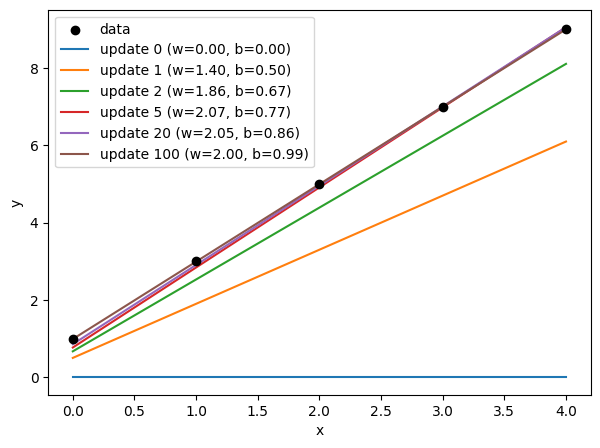

In [ ]:
path, history = gd(0.05, 100)

plt.figure(figsize=(7,5))
plt.scatter(x, y, color="black", zorder=5, label="data")
for i in [0, 1, 2, 5, 20, 100]:
    w_i, b_i = path[i]
    plt.plot(x, w_i * x + b_i, label=f"update {i} (w={w_i:.2f}, b={b_i:.2f})")
plt.xlabel("x"); plt.ylabel("y")
plt.legend()
plt.show()

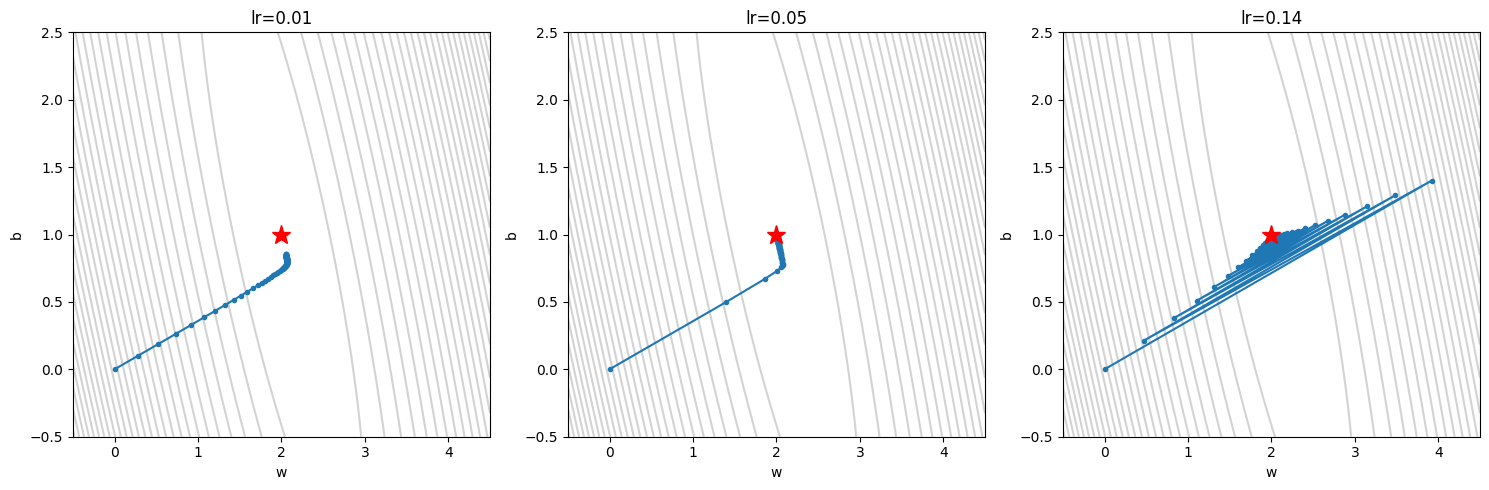

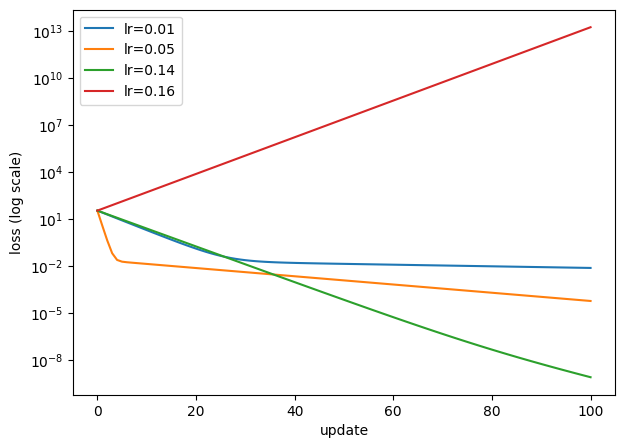

In [ ]:
ws = np.linspace(-0.5, 4.5, 200)
bs = np.linspace(-0.5, 2.5, 200)
W, B = np.meshgrid(ws, bs)

L_surface = np.zeros_like(W)
for i in range(len(x)):
    L_surface += (W * x[i] + B - y[i])**2
L_surface /= len(x)

lrs_contour = [0.01, 0.05, 0.14]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, lr in zip(axes, lrs_contour):
    p, h = gd(lr, 100)
    ax.contour(W, B, L_surface, levels=30, colors="lightgray")
    ax.plot(p[:, 0], p[:, 1], "o-", markersize=3)
    ax.plot(2, 1, "r*", markersize=14)
    ax.set_title(f"lr={lr}")
    ax.set_xlabel("w"); ax.set_ylabel("b")
plt.tight_layout()
plt.show()

lrs_loss = [0.01, 0.05, 0.14, 0.16]
plt.figure(figsize=(7,5))
for lr in lrs_loss:
    _, h = gd(lr, 100)
    plt.plot(h, label=f"lr={lr}")
plt.yscale("log")
plt.xlabel("update"); plt.ylabel("loss (log scale)")
plt.legend()
plt.show()

1. In B, which parameter gets close to its correct value first, w or b? Use the shape of the contours in C to explain why

w gets close to its correct value faster(1.4) and it's correct value is 2 and b = 0.5(while it's correct value is 1)

2. Describe the path for lr=0.14. Better or worse than lr=0.05 after 100 updates? What happens at lr=0.16?

at lr=0.14 the path oscillates.
it is better than lr = 0.05 because loss decreases slower with smaller learning rate.
At lr=0.16 the oscillations grow with every update, and the path
diverges

3. Run GD for the same number of updates with several candidate learning rates. Pick the largest learning rate that still shows a steady, non-oscillating decrease